# Prior sensitivity and derived orbital quantities

The experiment holds the photometric likelihood and all nuisance priors fixed. Eccentricity priors are specified conditionally for this observed transiting candidate: circular; truncated exponential scale 0.06; uniform on [0,0.8). The broad prior is a stress test. These are not intrinsic population priors.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd()/"src/analysis.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT/"src"))
import analysis
RESULTS = ROOT / "results/refined_20261104"

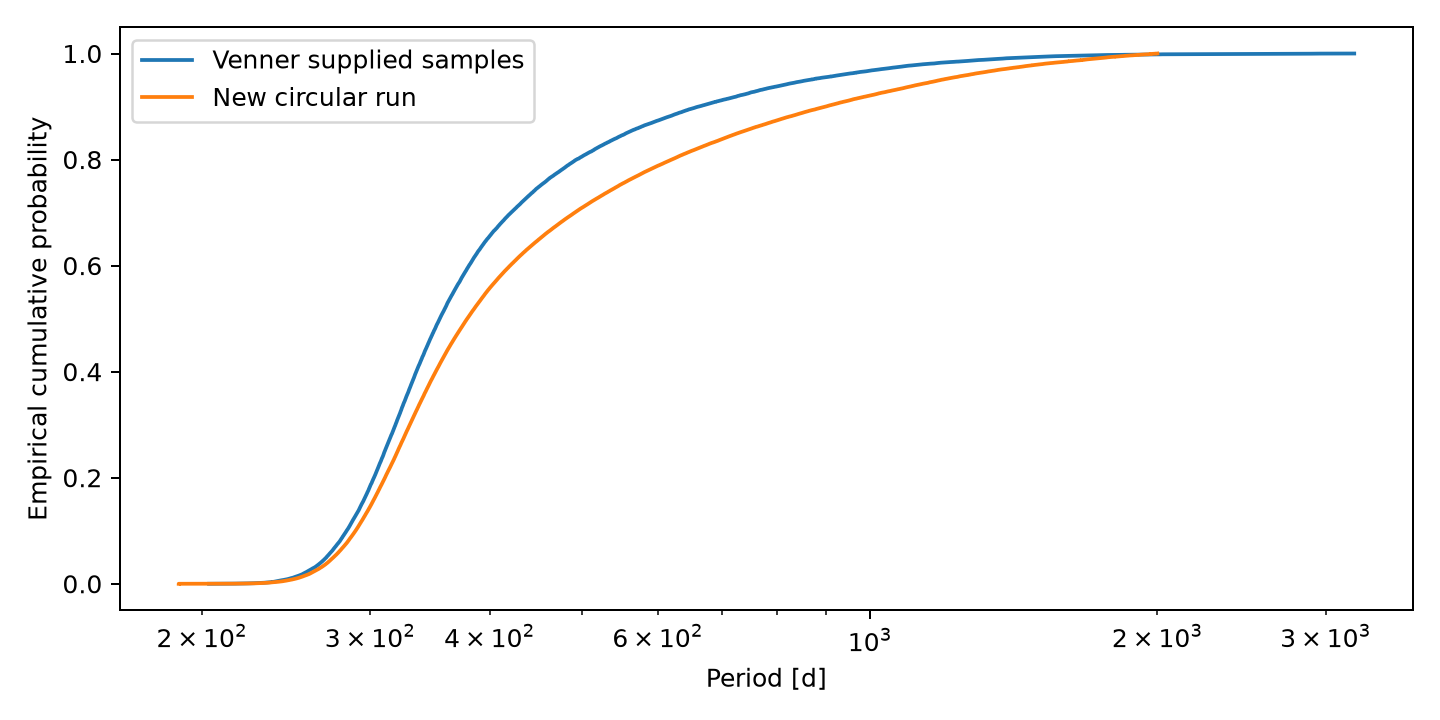

{
  "reference_quantiles": [
    295.73383082603925,
    354.74547614580695,
    542.4732380552962
  ],
  "new_quantiles": [
    302.89869518198424,
    378.9515293549816,
    703.6498326123778
  ],
  "ks_distance": 0.09959986111111108,
  "wasserstein_days": 71.82837912980295,
  "warning": "Distances are descriptive; do not interpret iid KS p-values for correlated MCMC samples. This is an approximate reproduction, not identical noise/detrending/selection modelling."
}


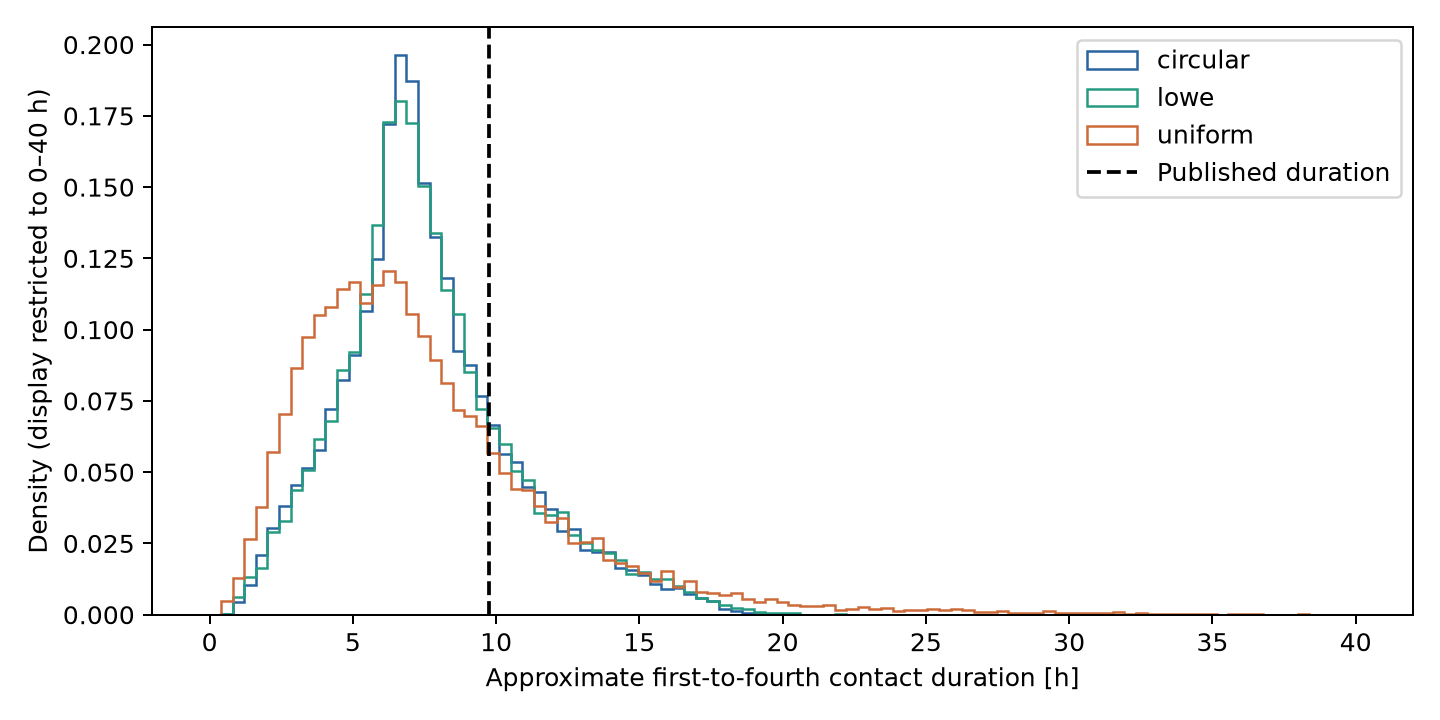

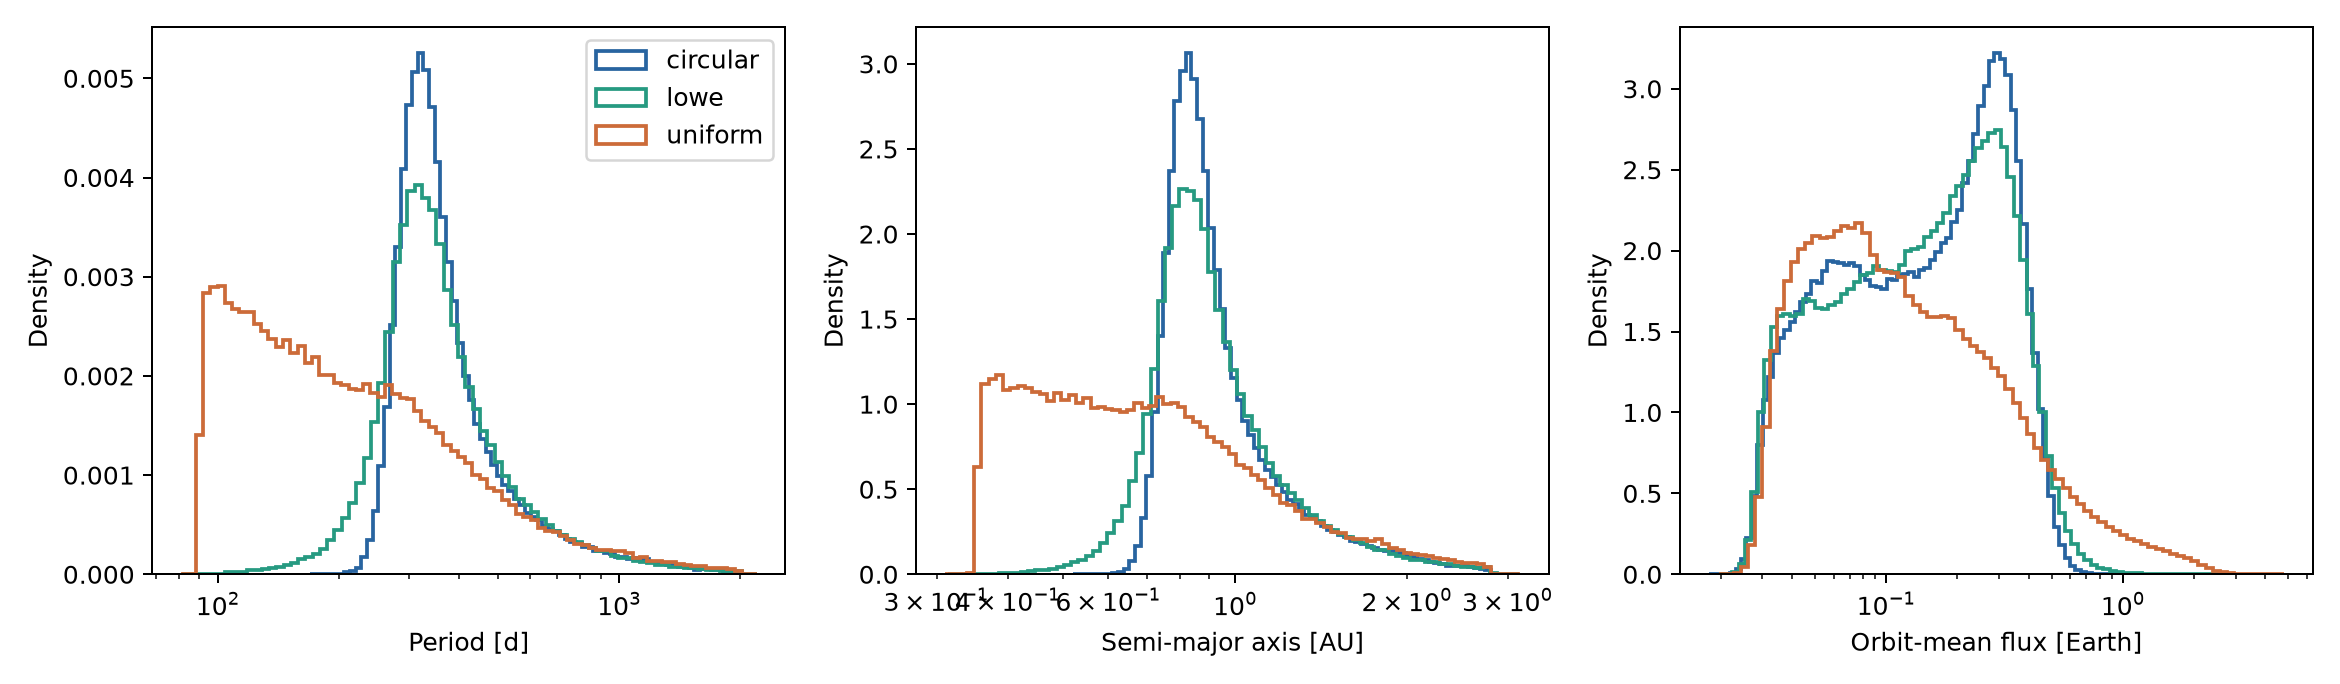

In [2]:
from IPython.display import Image, display
display(Image(filename=str(RESULTS/"circular_validation.png")))
print((RESULTS/"validation.json").read_text())
display(Image(filename=str(RESULTS/"prior_predictive_duration.png")))
display(Image(filename=str(RESULTS/"prior_sensitivity.png")))

In [3]:
import pandas as pd
table=pd.read_csv(RESULTS/"summary.csv")
display(table)

,model,quantity,q16,q50,q84
0,circular,period_days,302.898695,378.951529,703.649833
1,circular,eccentricity,0.000000,0.000000,0.000000
2,circular,semi_major_axis_AU,0.793223,0.921371,1.391182
3,circular,radius_Earth,1.005660,1.057896,1.123457
4,circular,flux_at_a_Earth,0.118882,0.267791,0.384097
5,circular,mean_flux_Earth,0.118882,0.267791,0.384097
6,circular,periastron_AU,0.793223,0.921371,1.391182
7,circular,apastron_AU,0.793223,0.921371,1.391182
8,circular,periastron_flux_Earth,0.118882,0.267791,0.384097
9,circular,apastron_flux_Earth,0.118882,0.267791,0.384097


## Irradiation and physical interpretation

$a=(M_*/M_\odot)^{1/3}(P/{\rm yr})^{2/3}\,{\rm AU}$; $r_{\rm peri,apo}=a(1\mp e)$; $S_a=L_*/a^2$; $\langle S\rangle=S_a/\sqrt{1-e^2}$; $S_{\rm peri,apo}=L_*/[a(1\mp e)]^2$.

The stellar radius is derived from sampled density and an external mass draw; luminosity follows radius and effective temperature. These external draws approximate their joint uncertainty because isochrone covariance is unavailable. Check period bounds and convergence before interpreting intervals. Orbital-mean flux is not a climate or habitability model.

In [4]:
for kind in ["circular", "lowe", "uniform"]:
    print(kind)
    print(json.loads((RESULTS/"summary.json").read_text())[kind])

circular
{'period_days': [302.89869518198424, 378.9515293549816, 703.6498326123778], 'eccentricity': [0.0, 0.0, 0.0], 'semi_major_axis_AU': [0.7932234288329449, 0.9213707326687598, 1.3911817261059016], 'radius_Earth': [1.0056599498466647, 1.057895707502338, 1.1234574405027153], 'flux_at_a_Earth': [0.11888160359201035, 0.26779112084972856, 0.38409650597181366], 'mean_flux_Earth': [0.11888160359201035, 0.26779112084972856, 0.38409650597181366], 'periastron_AU': [0.7932234288329449, 0.9213707326687598, 1.3911817261059016], 'apastron_AU': [0.7932234288329449, 0.9213707326687598, 1.3911817261059016], 'periastron_flux_Earth': [0.11888160359201035, 0.26779112084972856, 0.38409650597181366], 'apastron_flux_Earth': [0.11888160359201035, 0.26779112084972856, 0.38409650597181366], 'flux_ratio': [1.0, 1.0, 1.0], 'period_near_lower_bound_fraction': 0.0, 'period_near_upper_bound_fraction': 0.0061534722222222225, 'convergence_screen_passed': True}
lowe
{'period_days': [288.0674828529884, 384.60429554

## Analysis outputs
Use the figures, numerical tables and diagnostics in the results directory. See `docs/PROJECT_STATUS.md` for scientific caveats. TESS notebook 06 remains exploratory: a non-detection likelihood requires measured detection efficiency and real time coverage.
